# Face Recognition with Decision Trees, Bagging, and SAMME Boosting

This notebook prepares the Olivetti Faces data, creates and saves the fixed train/validation/test split using **seed = 003**, shows dataset/split visualizations, and then runs the assignment experiments and plots.

Run the notebook from top to bottom. The setup cell creates `olivetti_faces_final.npz`, which is also the file loaded by the implementation cells below. The split is generated once and saved with the data so later runs can reuse exactly the same indices.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.datasets import fetch_olivetti_faces

# Configuration: keep this seed consistent with the implementation you used.
SEED = 3
DATA_FILE = Path("olivetti_faces_final.npz")

# Fetch the dataset in its original order.
faces = fetch_olivetti_faces(shuffle=False)
X = faces.data.astype(np.float32, copy=True)
y = faces.target.astype(np.int64, copy=True)

assert X.shape == (400, 4096), f"Unexpected X shape: {X.shape}"
assert y.shape == (400,), f"Unexpected y shape: {y.shape}"
assert len(np.unique(y)) == 40

# Reproducible, stratified-by-identity split: 6 train, 2 validation, 2 test per identity.
rng = np.random.default_rng(SEED)
train_idx, val_idx, test_idx = [], [], []

for identity in np.unique(y):
    identity_indices = np.where(y == identity)[0].copy()
    rng.shuffle(identity_indices)
    train_idx.extend(identity_indices[:6])
    val_idx.extend(identity_indices[6:8])
    test_idx.extend(identity_indices[8:10])

train_idx = np.asarray(train_idx, dtype=np.int64)
val_idx = np.asarray(val_idx, dtype=np.int64)
test_idx = np.asarray(test_idx, dtype=np.int64)

# Validate that the split is complete, disjoint, and has the requested per-class counts.
all_idx = np.concatenate([train_idx, val_idx, test_idx])
assert len(all_idx) == 400 and len(np.unique(all_idx)) == 400
assert np.array_equal(np.sort(all_idx), np.arange(400))
for identity in np.unique(y):
    assert np.sum(y[train_idx] == identity) == 6
    assert np.sum(y[val_idx] == identity) == 2
    assert np.sum(y[test_idx] == identity) == 2

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

# Make a separate occluded test set: zero the central 16x16 region (rows/cols 24..39).
X_test_occluded = X_test.reshape(-1, 64, 64).copy()
X_test_occluded[:, 24:40, 24:40] = 0.0
X_test_occluded = X_test_occluded.reshape(-1, 4096)
y_test_occluded = y_test.copy()

# Save both the raw arrays and split-specific arrays for the implementation notebook cells.
np.savez_compressed(
    DATA_FILE,
    X=X, y=y,
    train_idx=train_idx, val_idx=val_idx, test_idx=test_idx,
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    X_test=X_test, y_test=y_test,
    X_test_occluded=X_test_occluded, y_test_occluded=y_test_occluded,
    seed=np.asarray(SEED, dtype=np.int64)
)

print(f"Dataset loaded: X={X.shape}, y={y.shape}, identities={len(np.unique(y))}")
print(f"Seed: {SEED:03d}")
print(f"Split sizes: train={len(train_idx)}, validation={len(val_idx)}, test={len(test_idx)}")
print(f"Saved reusable dataset and split to: {DATA_FILE.resolve()}")

Dataset loaded: X=(400, 4096), y=(400,), identities=40
Seed: 003
Split sizes: train=240, validation=80, test=80
Saved reusable dataset and split to: C:\Users\SAI RAJU\OneDrive\Desktop\praveen\MTECH\ML\Assignment-2\olivetti_faces_final.npz


## Dataset and split visualizations

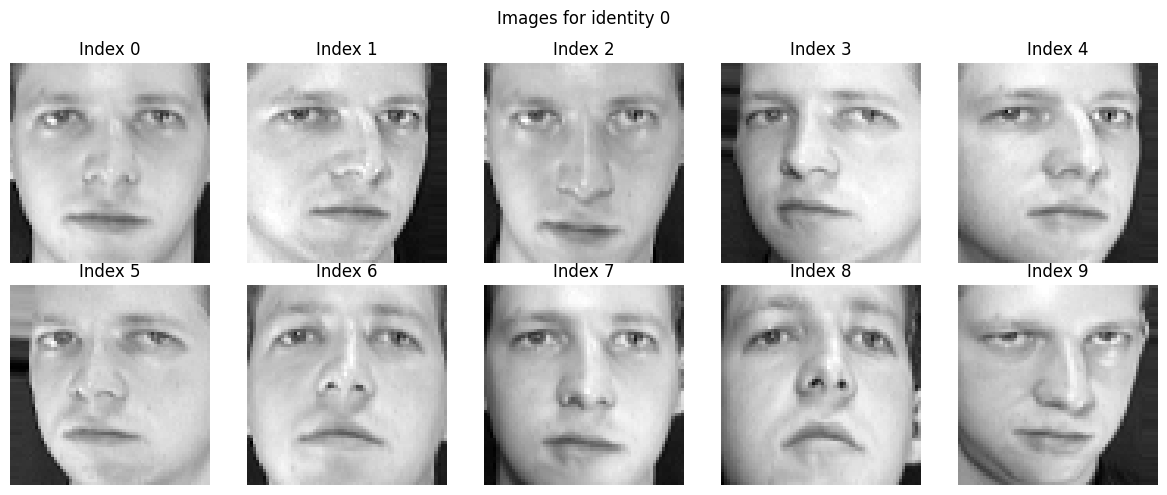

In [3]:
identity = np.unique(y)[0]
indices = np.where(y == identity)[0]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, idx in zip(axes.flat, indices):
    ax.imshow(X[idx].reshape(64, 64), cmap="gray")
    ax.set_title(f"Index {idx}")
    ax.axis("off")

plt.suptitle(f"Images for identity {identity}")
plt.tight_layout()
plt.show()

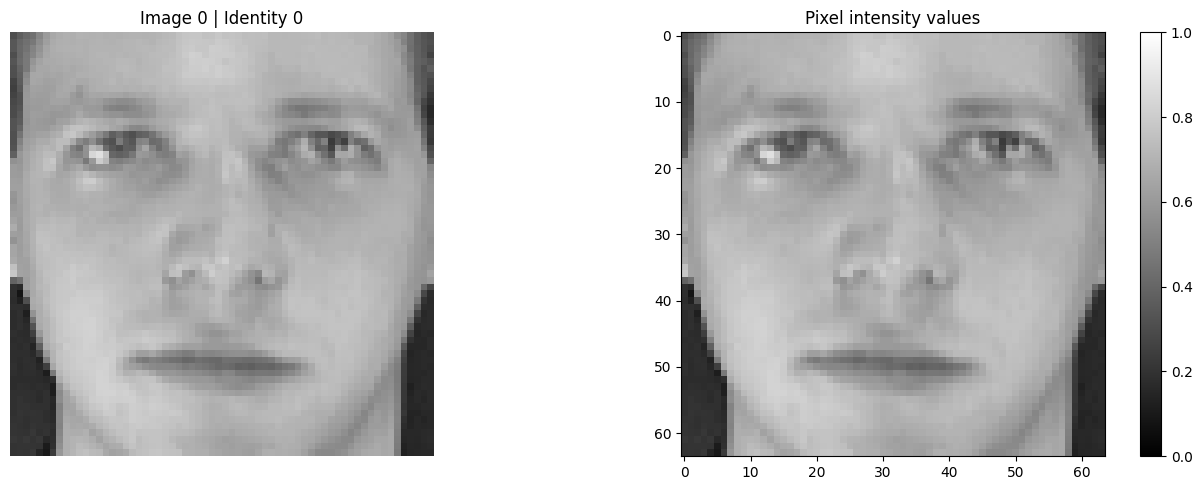

First 20 pixel values:
[0.30991736 0.3677686  0.41735536 0.44214877 0.5289256  0.607438
 0.6570248  0.677686   0.69008267 0.6859504  0.70247936 0.6983471
 0.6942149  0.6983471  0.69008267 0.6942149  0.69008267 0.6983471
 0.70247936 0.70247936]

Top-left 5 x 5 pixel matrix:
[[0.30991736 0.3677686  0.41735536 0.44214877 0.5289256 ]
 [0.3429752  0.40495867 0.43801653 0.47107437 0.553719  ]
 [0.3429752  0.41735536 0.45041323 0.5123967  0.57438016]
 [0.30578512 0.4090909  0.47107437 0.5247934  0.59504133]
 [0.33471075 0.4214876  0.4752066  0.58264464 0.6404959 ]]


In [4]:

image_index = 0
image_pixels = X[image_index]
image_2d = image_pixels.reshape(64, 64)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(image_2d, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Image {image_index} | Identity {y[image_index]}")
axes[0].axis("off")
im = axes[1].imshow(image_2d, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Pixel intensity values")
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

print("First 20 pixel values:")
print(image_pixels[:20])
print("\nTop-left 5 x 5 pixel matrix:")
print(image_2d[:5, :5])

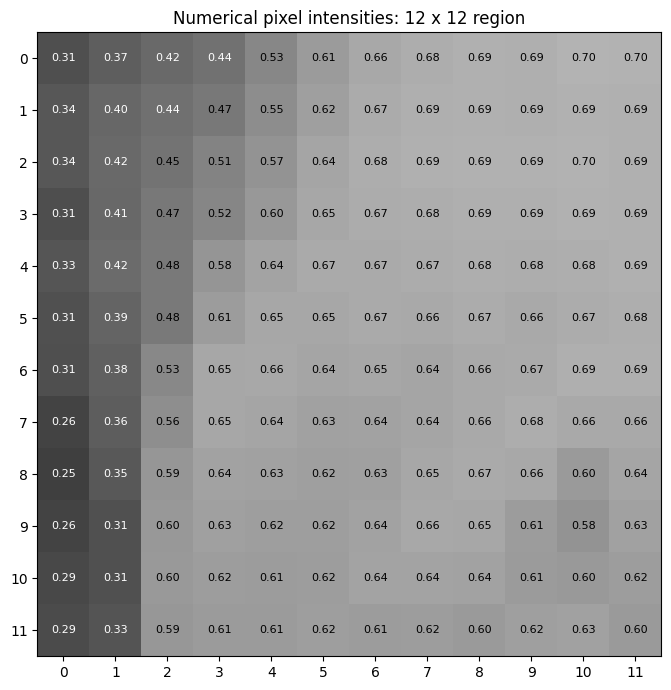

In [5]:
image_index = 0
image_2d = X[image_index].reshape(64, 64)

# Inspect the top-left 12 x 12 region
region = image_2d[:12, :12]

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(region, cmap="gray", vmin=0, vmax=1)

for r in range(region.shape[0]):
    for c in range(region.shape[1]):
        value = region[r, c]
        text_color = "white" if value < 0.45 else "black"
        ax.text(
            c, r, f"{value:.2f}",
            ha="center", va="center",
            color=text_color, fontsize=8
        )

ax.set_title("Numerical pixel intensities: 12 x 12 region")
ax.set_xticks(range(12))
ax.set_yticks(range(12))
plt.tight_layout()
plt.show()

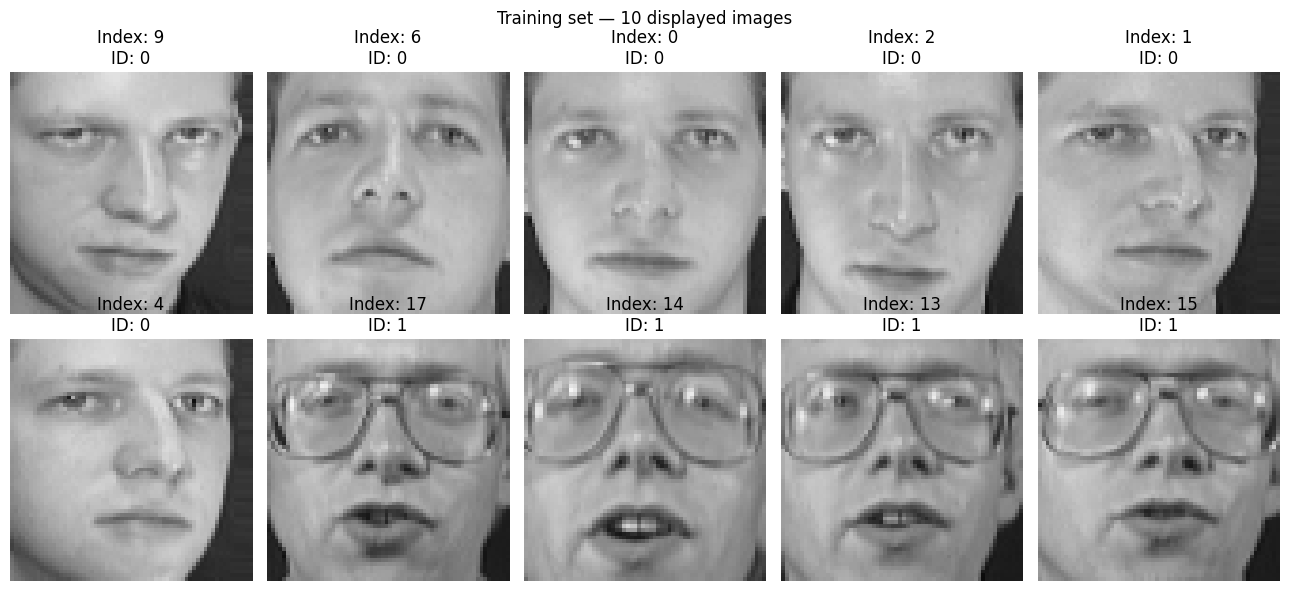

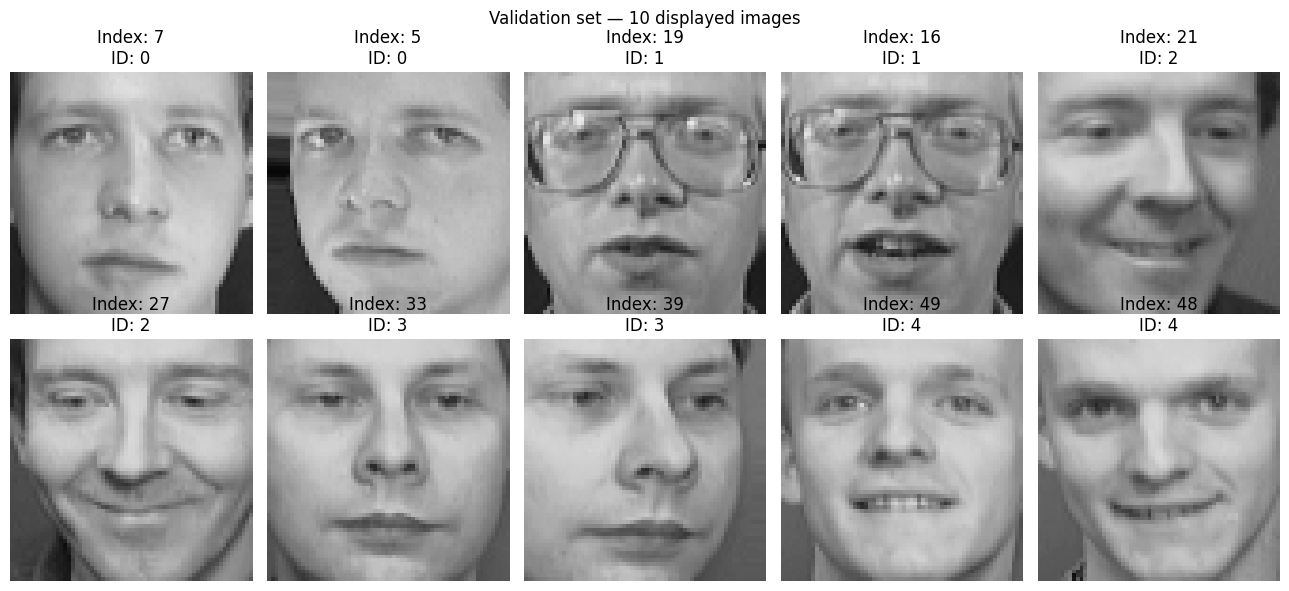

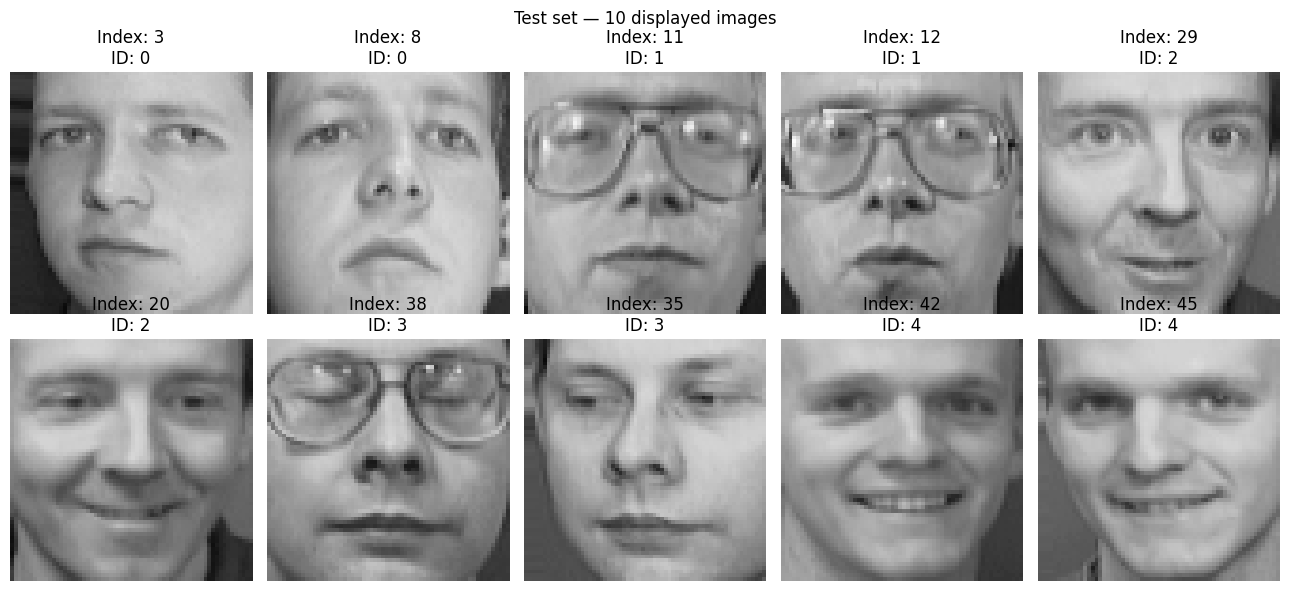

In [6]:
def show_split_images(X, y, indices, split_name, n_images=10):
    indices = indices[:n_images]

    fig, axes = plt.subplots(2, 5, figsize=(13, 6))

    for ax, idx in zip(axes.flat, indices):
        ax.imshow(
            X[idx].reshape(64, 64),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        ax.set_title(f"Index: {idx}\nID: {y[idx]}")
        ax.axis("off")

    plt.suptitle(f"{split_name} set — {len(indices)} displayed images")
    plt.tight_layout()
    plt.show()


show_split_images(X, y, train_idx, "Training")
show_split_images(X, y, val_idx, "Validation")
show_split_images(X, y, test_idx, "Test")

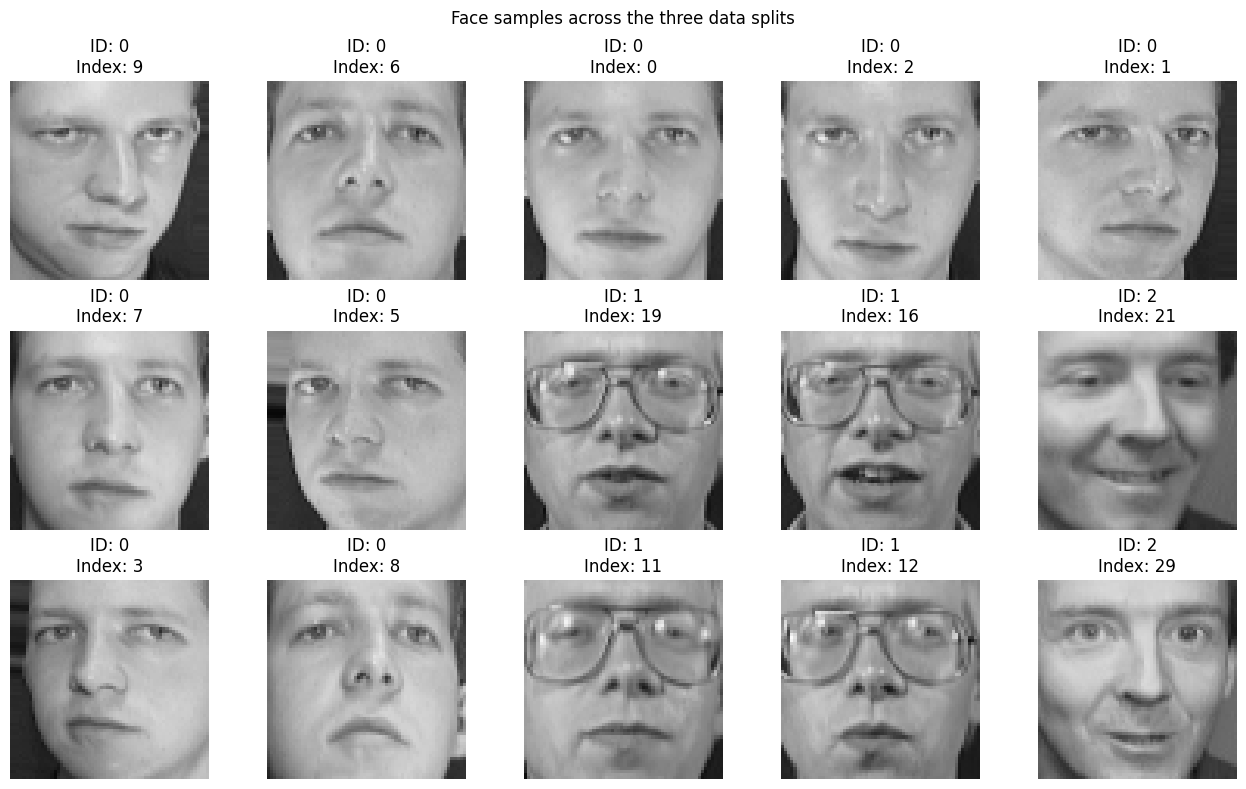

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(13, 8))

splits = [
    ("Train", train_idx),
    ("Validation", val_idx),
    ("Test", test_idx)
]

for row, (name, indices) in enumerate(splits):
    for col, idx in enumerate(indices[:5]):
        axes[row, col].imshow(
            X[idx].reshape(64, 64),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, col].set_title(
            f"ID: {y[idx]}\nIndex: {idx}"
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(name, fontsize=12)

plt.suptitle("Face samples across the three data splits")
plt.tight_layout()
plt.show()

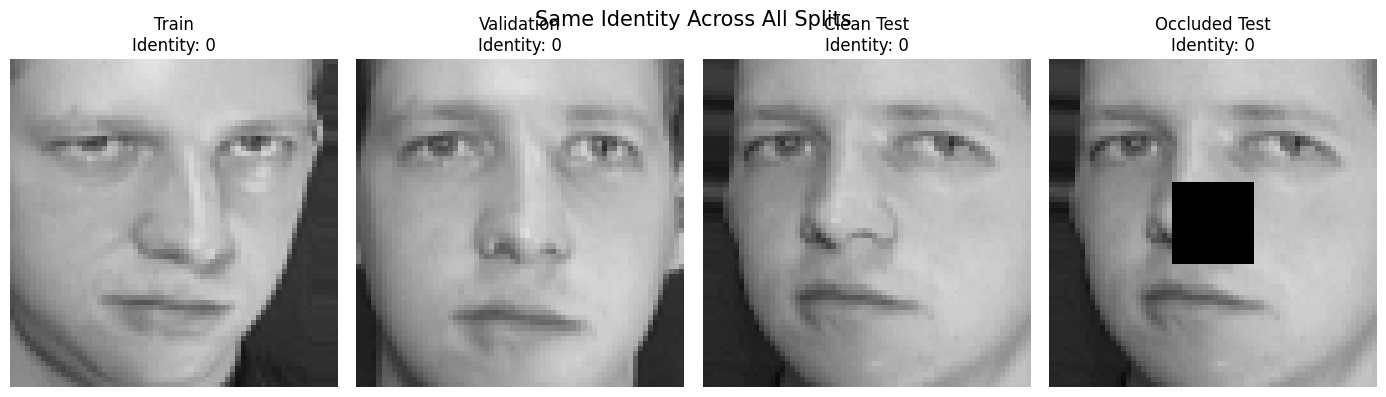

Identity: 0
Train original index: 9
Validation original index: 7
Test original index: 3
Occluded test position: 0


In [8]:

import numpy as np
import matplotlib.pyplot as plt

# Load your saved dataset and existing split
data = np.load("olivetti_faces_final.npz", allow_pickle=False)

X = data["X"]
y = data["y"]

train_idx = data["train_idx"]
val_idx = data["val_idx"]
test_idx = data["test_idx"]

X_test_occluded = data["X_test_occluded"]
y_test_occluded = data["y_test_occluded"]

# Select one identity that has images in every split
identity = np.unique(y)[0]

train_image_idx = train_idx[y[train_idx] == identity][0]
val_image_idx = val_idx[y[val_idx] == identity][0]
test_image_idx = test_idx[y[test_idx] == identity][0]

# Locate the corresponding occluded test image
occluded_position = np.where(test_idx == test_image_idx)[0][0]

# Prepare the four images
images = [
    X[train_image_idx].reshape(64, 64),
    X[val_image_idx].reshape(64, 64),
    X[test_image_idx].reshape(64, 64),
    X_test_occluded[occluded_position].reshape(64, 64)
]

titles = [
    f"Train\nIdentity: {identity}",
    f"Validation\nIdentity: {identity}",
    f"Clean Test\nIdentity: {identity}",
    f"Occluded Test\nIdentity: {identity}"
]

# Visualize side by side
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("Same Identity Across All Splits", fontsize=15)
plt.tight_layout()
plt.show()

print("Identity:", identity)
print("Train original index:", train_image_idx)
print("Validation original index:", val_image_idx)
print("Test original index:", test_image_idx)
print("Occluded test position:", occluded_position)
